In [8]:
import sys
from pathlib import Path

import yaml
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path('/Users/apple/Downloads/HUTECH/Thesis/FOTA_project').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.attacks.pbsm import PBSMAttack

with open(PROJECT_ROOT / 'configs' / 'attacks' / 'pbsm.yaml', 'r') as f:
    pbsm_cfg = yaml.safe_load(f)

SR = 22050
HOP_LENGTH = 256
WIN_LENGTH = 1024
N_FFT = 1024
N_MELS = 80

TRAIN_LEFT_DIR = PROJECT_ROOT / 'datasets' / 'raw' / 'train' / 'left'
raw_wav_files = sorted(TRAIN_LEFT_DIR.glob('*.wav'))
if not raw_wav_files:
    raise FileNotFoundError(f'No WAV files found in {TRAIN_LEFT_DIR}')

sample_wav = raw_wav_files[0]
original_audio, _ = librosa.load(sample_wav, sr=SR)

pbsm = PBSMAttack(
    target_label=0,
    poison_rate=pbsm_cfg['poison_rate'],
    sr=SR,
    n_fft=N_FFT,
    hop_length=pbsm_cfg['hop_length'],
    win_length=pbsm_cfg['win_length'],
    n_steps=pbsm_cfg['n_steps'],
    extend=pbsm_cfg['extend'],
    duration=pbsm_cfg['duration'],
)
triggered_audio = pbsm.inject_trigger(original_audio)

original_mel = librosa.feature.melspectrogram(
    y=original_audio,
    sr=SR,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    win_length=WIN_LENGTH,
    n_mels=N_MELS,
)
triggered_mel = librosa.feature.melspectrogram(
    y=triggered_audio,
    sr=SR,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    win_length=WIN_LENGTH,
    n_mels=N_MELS,
)

original_db = librosa.power_to_db(original_mel, ref=np.max)
triggered_db = librosa.power_to_db(triggered_mel, ref=np.max)

print(f'Using sample: {sample_wav.name}')
print(f'Original shape: {original_db.shape}')
print(f'PBSM shape: {triggered_db.shape}')
print(f'Original dB range: [{original_db.min():.2f}, {original_db.max():.2f}]')
print(f'PBSM dB range: [{triggered_db.min():.2f}, {triggered_db.max():.2f}]')


Using sample: 00176480_nohash_0.wav
Original shape: (80, 87)
PBSM shape: (80, 87)
Original dB range: [-80.00, 0.00]
PBSM dB range: [-80.00, 0.00]


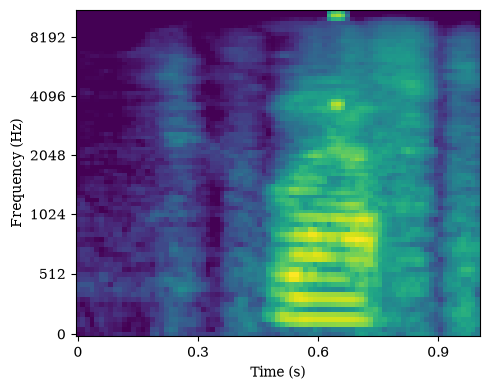

In [9]:
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 10,
    'axes.labelsize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
})

fig, ax = plt.subplots(figsize=(5, 4))
librosa.display.specshow(
    triggered_db,
    sr=SR,
    hop_length=HOP_LENGTH,
    x_axis='time',
    y_axis='mel',
    fmax=SR / 2,
    cmap='viridis',
    ax=ax,
)
ax.set_xlabel('Time (s)')
ax.set_ylabel('Frequency (Hz)')
# ax.set_title('PBSM Triggered Sample')
ax.set_xticks([0, 0.3, 0.6, 0.9])
ax.set_yticks([0, 512, 1024, 2048, 4096, 8192])
plt.tight_layout()
plt.show()
